# Computable Features: áp dụng cho bài toán dự đoán giá nhà
*Seminar The Art of Feature Engineering (Duboue), phần 3: Features, Expanded*

**Computable feature** là feature mới được **tính ra từ các feature đã có**, bằng các phép toán đơn giản kết hợp hiểu biết về lĩnh vực.
Theo Duboue, kỹ thuật này đặc biệt hữu ích khi model **không tự làm được** một phép toán nào đó trên feature. Ví dụ: model tuyến tính không tự nhân hai feature với nhau.

Notebook làm 3 việc:
1. Tạo **6 nhóm computable feature**: log, tổng, hiệu, tỉ lệ, tích, cờ nhị phân.
2. Dùng biểu đồ để kiểm tra từng feature mới có hợp lý không.
3. So sánh hai model có bản chất khác nhau: **Ridge** (tuyến tính) và **RandomForest** (cây quyết định). Mục tiêu là xem *nhóm feature nào giúp model nào, và vì sao*.

> Dữ liệu: Ames Housing (Kaggle), đã chia sẵn thành train 1166 căn và val 292 căn, mỗi căn có 79 cột.
> Đặt 4 file `X_train.csv`, `X_val.csv`, `Y_train.csv`, `Y_val.csv` cùng thư mục với notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score

# Màu dùng xuyên suốt: xanh = feature gốc / baseline, cam = computable feature
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#b5b3ad'
sns.set_theme(style='whitegrid', font_scale=0.95)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.color': '#e6e5e0', 'figure.dpi': 110})
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

## 1. Đọc dữ liệu

In [2]:
X_train = pd.read_csv('X_train.csv')
X_val = pd.read_csv('X_val.csv')
y_train = pd.read_csv('Y_train.csv')['SalePrice']   # đã là log(giá)
y_val = pd.read_csv('Y_val.csv')['SalePrice']

print('Train:', X_train.shape, '| Val:', X_val.shape)
print('Số cột số:', X_train.select_dtypes('number').shape[1],
      '| Số cột phân loại:', X_train.select_dtypes(exclude='number').shape[1])

Train: (1166, 79) | Val: (292, 79)
Số cột số: 36 | Số cột phân loại: 43


Target `SalePrice` trong file **đã được lấy log sẵn**. Biểu đồ dưới cho thấy lý do: giá gốc bị lệch phải (vài căn rất đắt), còn sau khi lấy log thì phân phối gần đối xứng.

Vì vậy mọi RMSE trong notebook đều tính trên log(giá). Có thể hiểu gần đúng đây là **sai số theo tỉ lệ**: RMSE 0.12 tương đương dự đoán lệch khoảng 12%.

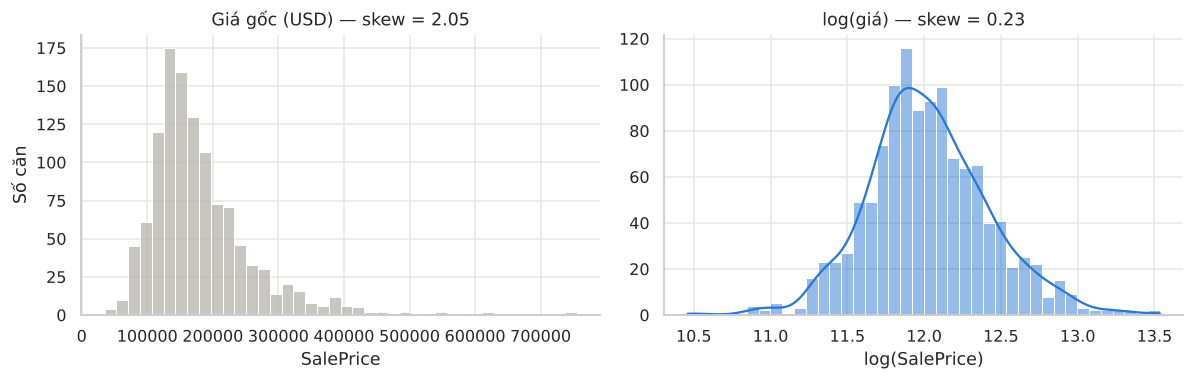

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(np.exp(y_train), bins=40, color=GRAY, ax=axes[0])
axes[0].set(title=f'Giá gốc (USD) — skew = {np.exp(y_train).skew():.2f}', xlabel='SalePrice', ylabel='Số căn')
sns.histplot(y_train, bins=40, color=BLUE, kde=True, ax=axes[1])
axes[1].set(title=f'log(giá) — skew = {y_train.skew():.2f}', xlabel='log(SalePrice)', ylabel='')
plt.tight_layout(); plt.show()

## 2. Tạo computable feature

| Nhóm | Phép toán | Feature tạo ra | Ý nghĩa |
|---|---|---|---|
| **Log** | biến đổi 1 feature | `log_LotArea`, `log_GrLivArea`, … | kéo các cột lệch phải về gần đối xứng |
| **Tổng** | a + b + c | `TotalSF`, `TotalBath`, `TotalPorchSF` | gộp các phần của cùng một đại lượng |
| **Hiệu** | a − b | `HouseAge`, `RemodAge`, `GarageAge` | đổi "năm xây" thành "tuổi nhà lúc bán" |
| **Tỉ lệ** | a / b | `AreaPerRoom`, `LivLotRatio`, `BsmtFinRatio` | mật độ, mức độ sử dụng |
| **Tích** | a × b | `Qual_x_LivArea`, `Qual_x_TotalSF`, `Qual_x_Cond` | tương tác: chất lượng × diện tích |
| **Cờ** | a > 0 → 1/0 | `Has2ndFlr`, `HasGarage`, `IsNew`, … | có hay không có |

Mỗi nhóm là một hàm riêng để sau này dễ thử từng nhóm một.
Tất cả các hàm chỉ tính **trên từng dòng**, không dùng thống kê của cả tập (như mean hay median), nên có thể áp dụng cho cả train và val mà **không bị data leakage**.

In [4]:
# Mỗi hàm = một kỹ thuật computable feature. Tất cả chỉ tính trên TỪNG DÒNG,
# không dùng thống kê của cả tập -> áp dụng cho train/val đều không bị leakage.

def add_log(df):          # 1) Biến đổi một feature: log cho các cột lệch phải
    df = df.copy()
    for col in ['LotArea', 'GrLivArea', '1stFlrSF', 'LotFrontage', 'MasVnrArea']:
        df['log_' + col] = np.log1p(df[col])
    return df

def add_sums(df):         # 2) Tổng: gộp các phần của cùng một đại lượng
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
    df['TotalPorchSF'] = (df['WoodDeckSF'] + df['OpenPorchSF'] + df['EnclosedPorch']
                          + df['3SsnPorch'] + df['ScreenPorch'])
    return df

def add_diffs(df):        # 3) Hiệu: đổi "năm" thành "tuổi" tại thời điểm bán
    df = df.copy()
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    df['GarageAge'] = df['YrSold'] - df['GarageYrBlt']   # NaN nếu không có garage
    return df

def add_ratios(df):       # 4) Tỉ lệ: mật độ / mức độ sử dụng
    df = df.copy()
    df['AreaPerRoom'] = df['GrLivArea'] / df['TotRmsAbvGrd']
    df['LivLotRatio'] = df['GrLivArea'] / df['LotArea']
    df['BsmtFinRatio'] = ((df['BsmtFinSF1'] + df['BsmtFinSF2'])
                          / df['TotalBsmtSF'].replace(0, np.nan)).fillna(0)
    return df

def add_products(df):     # 5) Tích (tương tác): chất lượng x diện tích
    df = df.copy()
    total_sf = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['Qual_x_LivArea'] = df['OverallQual'] * df['GrLivArea']
    df['Qual_x_TotalSF'] = df['OverallQual'] * total_sf
    df['Qual_x_Cond'] = df['OverallQual'] * df['OverallCond']
    return df

def add_flags(df):        # 6) Cờ nhị phân: có / không
    df = df.copy()
    df['Has2ndFlr'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
    df['IsNew'] = (df['YrSold'] - df['YearBuilt'] <= 1).astype(int)
    return df

GROUPS = {'Log': add_log, 'Tổng': add_sums, 'Hiệu': add_diffs,
          'Tỉ lệ': add_ratios, 'Tích': add_products, 'Cờ': add_flags}

def add_all(df):
    for f in GROUPS.values():
        df = f(df)
    return df

Xtr_cf, Xva_cf = add_all(X_train), add_all(X_val)
new_cols = [c for c in Xtr_cf.columns if c not in X_train.columns]
print(f'Đã thêm {len(new_cols)} computable feature:')
print(new_cols)

Đã thêm 23 computable feature:
['log_LotArea', 'log_GrLivArea', 'log_1stFlrSF', 'log_LotFrontage', 'log_MasVnrArea', 'TotalSF', 'TotalBath', 'TotalPorchSF', 'HouseAge', 'RemodAge', 'GarageAge', 'AreaPerRoom', 'LivLotRatio', 'BsmtFinRatio', 'Qual_x_LivArea', 'Qual_x_TotalSF', 'Qual_x_Cond', 'Has2ndFlr', 'HasGarage', 'HasBsmt', 'HasFireplace', 'IsRemodeled', 'IsNew']


### 2.1 Biến đổi một feature: log

             skew trước  skew sau  r trước  r sau
LotArea           12.30     -0.03     0.26   0.41
GrLivArea          1.08      0.00     0.73   0.74
1stFlrSF           0.89      0.04     0.62   0.60
LotFrontage        1.76     -0.77     0.37   0.37
MasVnrArea         2.44      0.50     0.47   0.43


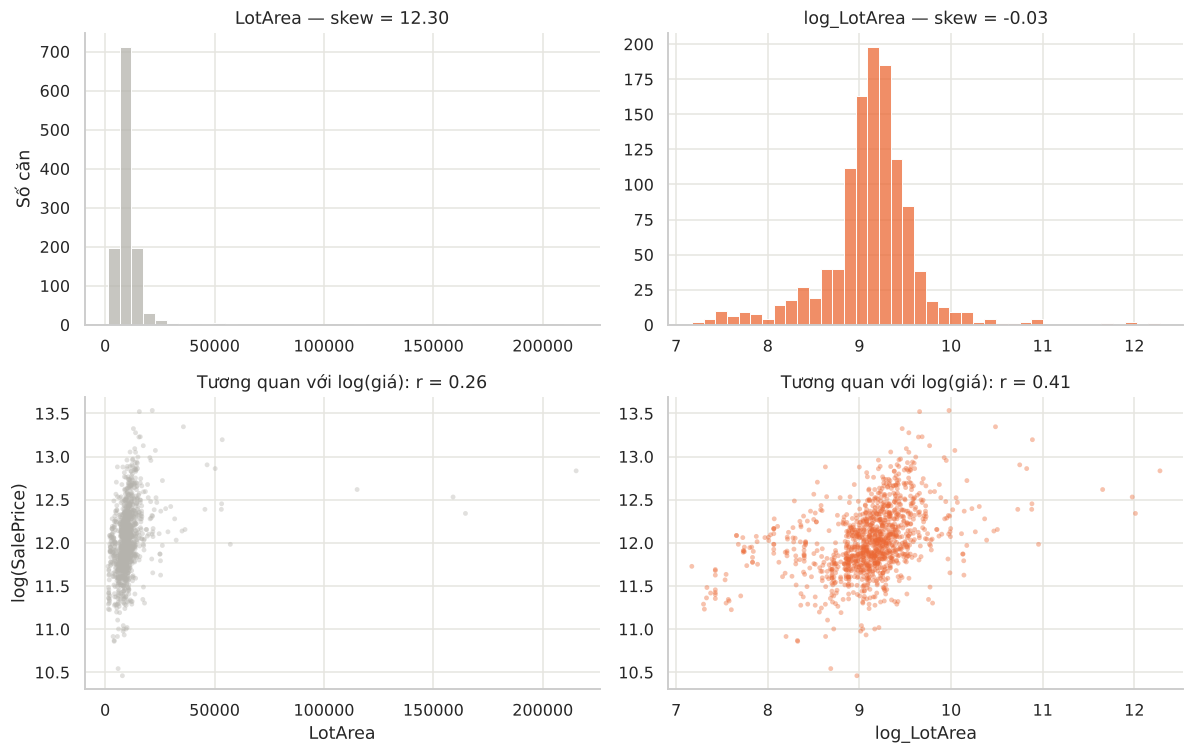

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (col, color) in enumerate([('LotArea', GRAY), ('log_LotArea', ORANGE)]):
    x = Xtr_cf[col]
    sns.histplot(x, bins=40, color=color, ax=axes[0, j])
    axes[0, j].set(title=f'{col} — skew = {x.skew():.2f}', xlabel='', ylabel='Số căn' if j == 0 else '')
    axes[1, j].scatter(x, y_train, s=10, alpha=0.4, color=color, edgecolor='none')
    axes[1, j].set(title=f'Tương quan với log(giá): r = {x.corr(y_train):.2f}',
                   xlabel=col, ylabel='log(SalePrice)' if j == 0 else '')
plt.tight_layout(); plt.show()

skew_tbl = pd.DataFrame({
    'skew trước': [X_train[c].skew() for c in ['LotArea', 'GrLivArea', '1stFlrSF', 'LotFrontage', 'MasVnrArea']],
    'skew sau': [Xtr_cf['log_' + c].skew() for c in ['LotArea', 'GrLivArea', '1stFlrSF', 'LotFrontage', 'MasVnrArea']],
    'r trước': [X_train[c].corr(y_train) for c in ['LotArea', 'GrLivArea', '1stFlrSF', 'LotFrontage', 'MasVnrArea']],
    'r sau': [Xtr_cf['log_' + c].corr(y_train) for c in ['LotArea', 'GrLivArea', '1stFlrSF', 'LotFrontage', 'MasVnrArea']],
}, index=['LotArea', 'GrLivArea', '1stFlrSF', 'LotFrontage', 'MasVnrArea']).round(2)
print(skew_tbl)

**Nhận xét:**
- `LotArea` lệch rất mạnh (skew 12.3) vì có vài lô đất cực lớn (trên 100.000 sqft) làm phần lớn dữ liệu bị dồn về một góc. Sau khi lấy log, skew gần bằng 0 và **tương quan với giá tăng từ 0.26 lên 0.41**, vì quan hệ đã gần tuyến tính hơn.
- `GrLivArea` và `1stFlrSF` chỉ lệch nhẹ, nên lấy log làm phân phối đẹp hơn nhưng tương quan gần như không đổi.
- Log **không phải lúc nào cũng tốt**. `MasVnrArea` có rất nhiều giá trị 0 nên log không giải quyết được "cột 0" đó, và tương quan còn giảm (0.47 xuống 0.43). `LotFrontage` thì bị lệch ngược sang trái (skew −0.77).
- Vì vậy ở đây ta **thêm cột log bên cạnh cột gốc** chứ không thay thế, để model tự chọn cột hữu ích hơn.

### 2.2 Feature mới có tương quan với giá mạnh hơn feature gốc không?

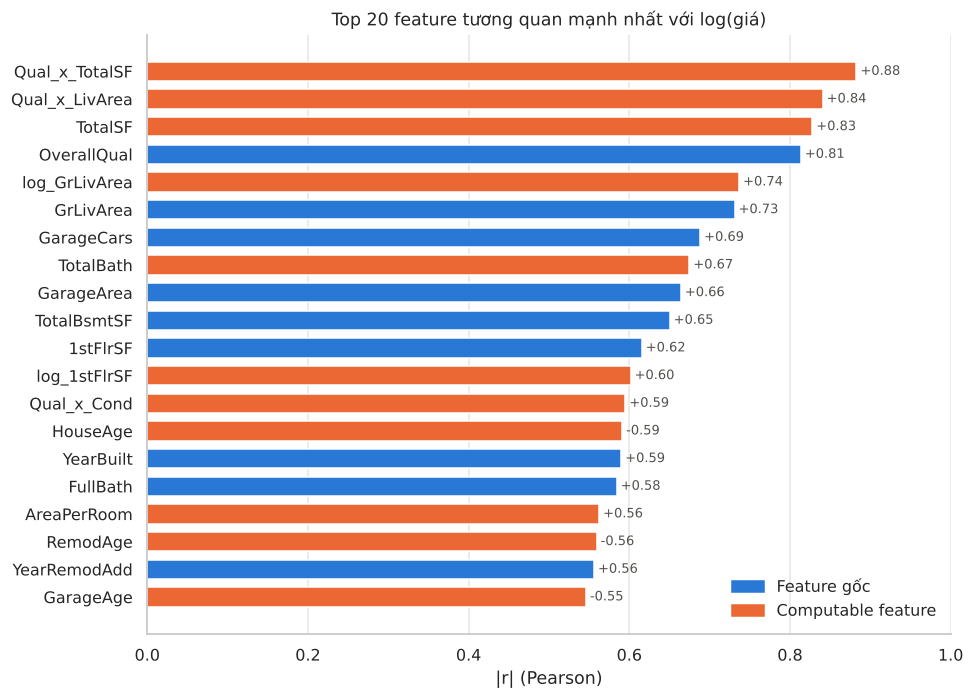

In [6]:
corr = Xtr_cf.select_dtypes('number').corrwith(y_train).dropna()
top = corr.abs().sort_values(ascending=False).head(20)[::-1]
colors = [ORANGE if c in new_cols else BLUE for c in top.index]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.values, color=colors, height=0.7)
for i, v in enumerate(top.values):
    ax.text(v + 0.005, i, f'{corr[top.index[i]]:+.2f}', va='center', fontsize=8.5, color='#52514e')
ax.set(title='Top 20 feature tương quan mạnh nhất với log(giá)', xlabel='|r| (Pearson)', xlim=(0, 1))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=['Feature gốc', 'Computable feature'], loc='lower right', frameon=False)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

**Nhận xét:**
- **Ba feature tương quan mạnh nhất đều là computable feature**: `Qual_x_TotalSF` (0.88), `Qual_x_LivArea` (0.84) và `TotalSF` (0.83). Cả ba đều vượt feature gốc mạnh nhất là `OverallQual` (0.81).
- `HouseAge` có r = −0.59, đúng bằng `YearBuilt` (+0.59) nhưng ngược dấu. Lý do là `YrSold` chỉ dao động trong 2006–2010, nên `HouseAge` ≈ hằng số − `YearBuilt`. Về mặt thông tin, hai cột này gần như trùng nhau.
- Lưu ý: **tương quan đơn biến cao chưa chắc giúp được model**, vì model có thể đã tự suy ra thông tin đó từ các cột gốc. Phần 3 sẽ kiểm chứng điều này.

### 2.3 Tích (tương tác): chất lượng × diện tích
Giả thuyết: một sqft trong nhà chất lượng cao đáng giá hơn một sqft trong nhà chất lượng thấp. Nếu đúng, giá sẽ phụ thuộc vào **tích** của hai feature này.

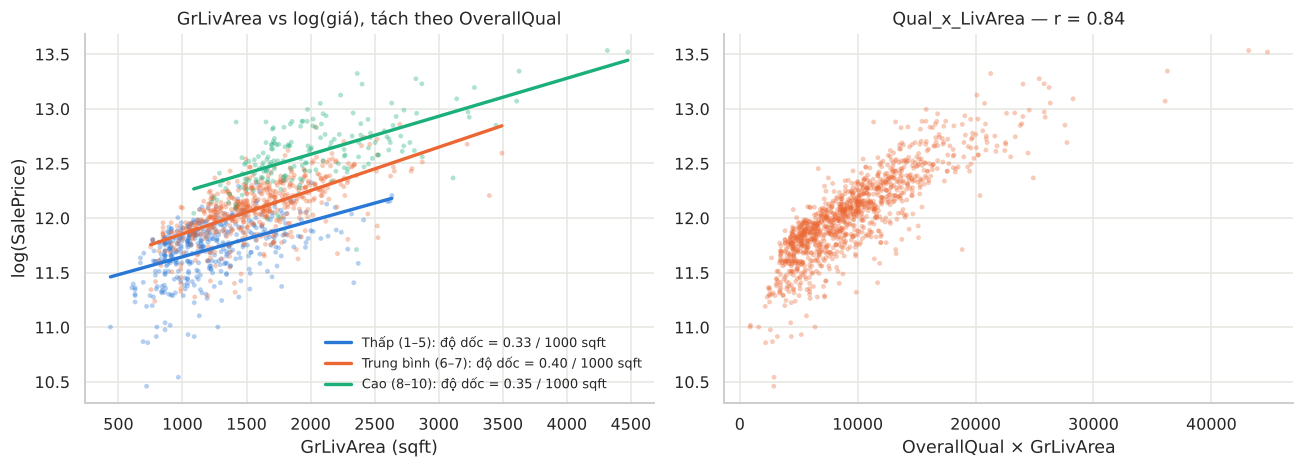

In [7]:
groups = pd.cut(X_train['OverallQual'], [0, 5, 7, 10], labels=['Thấp (1–5)', 'Trung bình (6–7)', 'Cao (8–10)'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for g, color in zip(groups.cat.categories, [BLUE, ORANGE, AQUA]):
    m = groups == g
    x, y = X_train.loc[m, 'GrLivArea'], y_train[m]
    a, b = np.polyfit(x, y, 1)
    axes[0].scatter(x, y, s=10, alpha=0.35, color=color, edgecolor='none')
    xs = np.linspace(x.min(), x.max(), 50)
    axes[0].plot(xs, a * xs + b, color=color, lw=2.2, label=f'{g}: độ dốc = {a * 1000:.2f} / 1000 sqft')
axes[0].set(title='GrLivArea vs log(giá), tách theo OverallQual', xlabel='GrLivArea (sqft)', ylabel='log(SalePrice)')
axes[0].legend(frameon=False, fontsize=8.5, loc='lower right')

x = Xtr_cf['Qual_x_LivArea']
axes[1].scatter(x, y_train, s=10, alpha=0.35, color=ORANGE, edgecolor='none')
axes[1].set(title=f'Qual_x_LivArea — r = {x.corr(y_train):.2f}', xlabel='OverallQual × GrLivArea', ylabel='')
plt.tight_layout(); plt.show()

**Nhận xét:**
- Bên phải, `Qual_x_LivArea` có quan hệ khá rõ với giá (r = 0.84).
- Bên trái là điểm thú vị: trên thang **log(giá)**, ba đường hồi quy **gần như song song** (độ dốc từ 0.33 đến 0.40 trên 1000 sqft). Nghĩa là chất lượng chủ yếu **đẩy cả đường lên cao hơn** chứ không làm đường dốc hơn nhiều.
- Lý do: target đã được lấy log, mà log(a × b) = log(a) + log(b). Quan hệ *nhân* trên giá gốc đã trở thành quan hệ *cộng* trên log(giá).
- **Dự đoán:** feature tích sẽ **ít giúp Ridge**, vì một model tuyến tính đã cộng được các feature với nhau. Phần 3 sẽ kiểm chứng.

### 2.4 Hiệu (tuổi nhà) và cờ nhị phân

Số căn mỗi cờ (=1): {'IsNew': 123, 'Has2ndFlr': 503, 'HasFireplace': 614, 'IsRemodeled': 565}


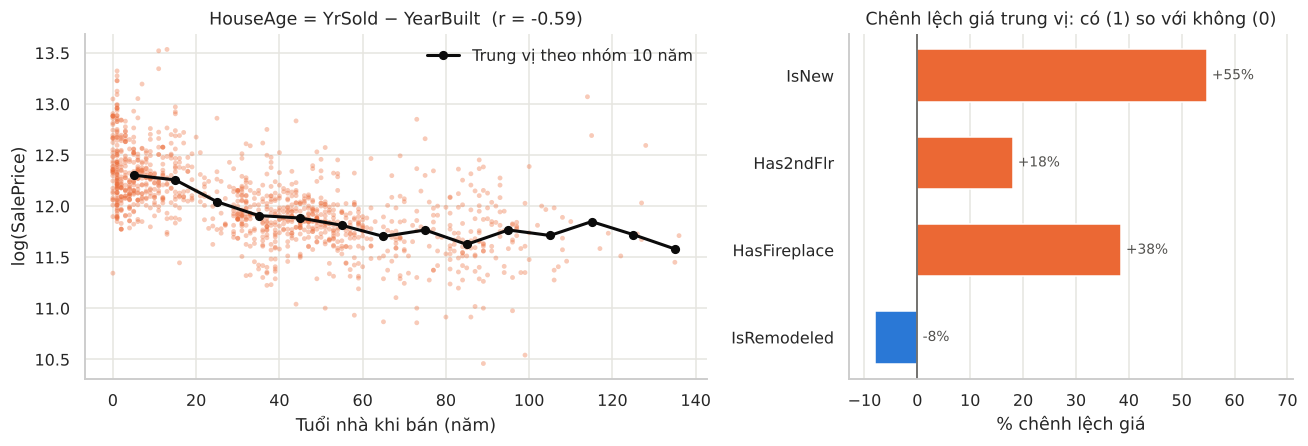

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.4, 1]})
axes[0].scatter(Xtr_cf['HouseAge'], y_train, s=10, alpha=0.35, color=ORANGE, edgecolor='none')
age_bin = (Xtr_cf['HouseAge'] // 10) * 10 + 5
trend = y_train.groupby(age_bin).median()
axes[0].plot(trend.index, trend.values, color='#0b0b0b', lw=2, marker='o', ms=5, label='Trung vị theo nhóm 10 năm')
axes[0].set(title=f'HouseAge = YrSold − YearBuilt  (r = {Xtr_cf["HouseAge"].corr(y_train):.2f})',
            xlabel='Tuổi nhà khi bán (năm)', ylabel='log(SalePrice)')
axes[0].legend(frameon=False)

flag_cols = ['IsNew', 'Has2ndFlr', 'HasFireplace', 'IsRemodeled']
diffs = [y_train[Xtr_cf[c] == 1].median() - y_train[Xtr_cf[c] == 0].median() for c in flag_cols]
pct = (np.exp(diffs) - 1) * 100
axes[1].barh(flag_cols[::-1], pct[::-1], color=[ORANGE if p > 0 else BLUE for p in pct[::-1]], height=0.6)
for i, p in enumerate(pct[::-1]):
    axes[1].text(max(p, 0) + 1, i, f'{p:+.0f}%', va='center', fontsize=9, color='#52514e')
axes[1].axvline(0, color='#52514e', lw=1)
axes[1].set(title='Chênh lệch giá trung vị: có (1) so với không (0)', xlabel='% chênh lệch giá')
axes[1].set_xlim(pct.min() - 5, pct.max() * 1.3)
axes[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

print('Số căn mỗi cờ (=1):', {c: int(Xtr_cf[c].sum()) for c in flag_cols})

**Nhận xét:**
- **HouseAge**: giá giảm nhanh trong khoảng 30 năm đầu, sau đó gần như đi ngang. Quan hệ này **không tuyến tính**.
- **Cờ**: nhà mới (`IsNew`, 123 căn) có giá trung vị cao hơn khoảng 55%, nhà có lò sưởi cao hơn khoảng 38%, nhà có tầng 2 cao hơn khoảng 18%.
- `IsRemodeled` lại **thấp hơn 8%**. Điều này không có nghĩa là sửa nhà làm giảm giá. Nhà được sửa thường là nhà cũ: trung vị tuổi của nhà đã sửa là 51 năm, so với 30 năm ở nhà chưa sửa. Đây là ví dụ về **biến gây nhiễu (confounding)**: chênh lệch nhìn từ một biến không phản ánh quan hệ nhân quả.
- Ngoài ra, cột `YearRemodAdd` có 143 căn ghi đúng năm 1950. Đây khả năng cao là giá trị mặc định của dữ liệu, nên cờ `IsRemodeled` cũng bị nhiễu một phần.

### 2.5 Cẩn thận: feature mới trùng thông tin với feature gốc

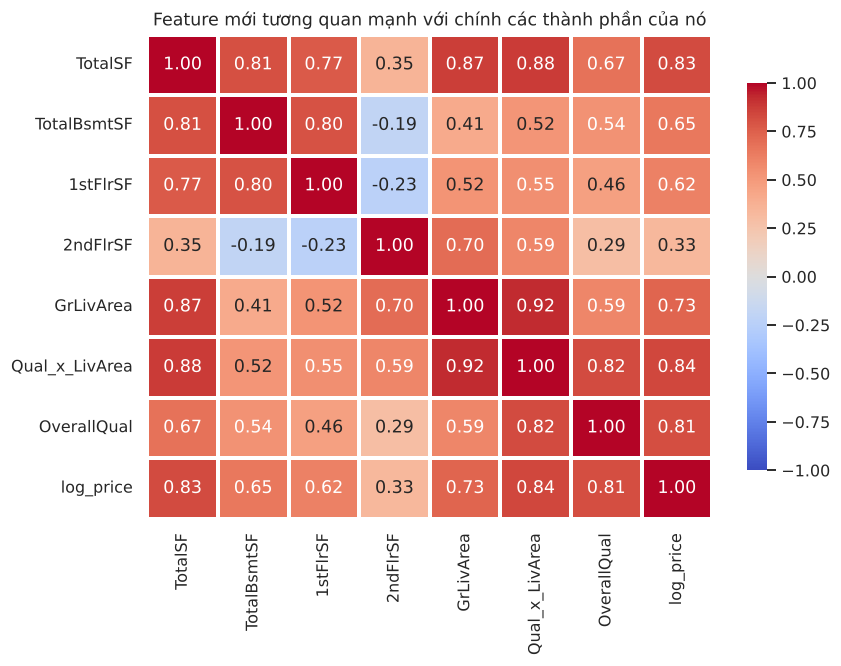

In [9]:
cols = ['TotalSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'Qual_x_LivArea', 'OverallQual']
cm = Xtr_cf[cols].assign(log_price=y_train).corr()
plt.figure(figsize=(8, 6.2))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=1.5, linecolor='white', cbar_kws={'shrink': 0.8})
plt.title('Feature mới tương quan mạnh với chính các thành phần của nó')
plt.tight_layout(); plt.show()

**Nhận xét:** `TotalSF` tương quan 0.87 với `GrLivArea`, còn `Qual_x_LivArea` tương quan 0.92 với `GrLivArea`.
Computable feature được tạo từ chính các cột gốc nên **chắc chắn sẽ trùng thông tin** với chúng, gây đa cộng tuyến.
Đây là lý do chương 3 (mở rộng feature) luôn đi cùng chương 4 (feature selection, giảm bớt feature). Trong notebook này, Ridge có regularization nên chịu được mức trùng lặp này.

## 3. Thử nghiệm: baseline vs + computable feature

- **Baseline**: 79 cột gốc. **+ Computable**: 79 cột gốc cộng 23 cột mới.
- Preprocessing **giống hệt nhau** cho cả hai: cột số được điền median rồi chuẩn hoá (StandardScaler); cột phân loại được điền "None" rồi one-hot.
- Mọi bước nằm trong `Pipeline` và chỉ được fit trên train, nên tránh được leakage.
- Hai model: **RidgeCV** (tuyến tính, tự chọn alpha) và **RandomForest** (200 cây).
- Có hai cách đánh giá: RMSE trên **tập val** và RMSE **5-fold CV trên train**. Tập val chỉ có 292 căn nên kết quả dễ bị nhiễu; CV cho con số ổn định hơn.

In [10]:
def make_model(kind):
    num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    cat = make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),
                        OneHotEncoder(handle_unknown='ignore'))
    prep = make_column_transformer((num, make_column_selector(dtype_include='number')),
                                   (cat, make_column_selector(dtype_exclude='number')))
    if kind == 'Ridge':
        reg = RidgeCV(alphas=np.logspace(-1, 3, 30))
    else:
        reg = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    return make_pipeline(prep, reg)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

kf = KFold(n_splits=5, shuffle=True, random_state=0)
def cv_rmse(kind, X):   # RMSE trung bình 5-fold trên tập train
    return -cross_val_score(make_model(kind), X, y_train, cv=kf,
                            scoring='neg_root_mean_squared_error').mean()

results, models = [], {}
for kind in ['Ridge', 'RandomForest']:
    for name, Xtr, Xva in [('Baseline', X_train, X_val), ('+ Computable', Xtr_cf, Xva_cf)]:
        model = make_model(kind).fit(Xtr, y_train)
        models[(kind, name)] = model
        results.append({'Model': kind, 'Feature set': name,
                        'RMSE val': rmse(y_val, model.predict(Xva)), 'RMSE CV': cv_rmse(kind, Xtr)})

res = pd.DataFrame(results)
print(res.round(4).to_string(index=False))

       Model  Feature set  RMSE val  RMSE CV
       Ridge     Baseline    0.1229   0.1145
       Ridge + Computable    0.1170   0.1128
RandomForest     Baseline    0.1441   0.1406
RandomForest + Computable    0.1403   0.1337


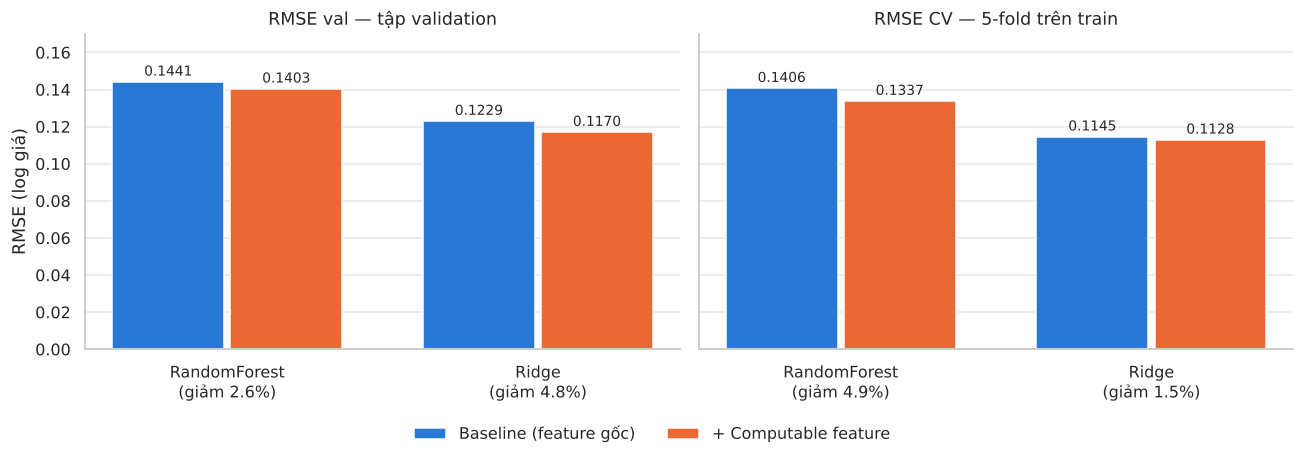

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, metric in zip(axes, ['RMSE val', 'RMSE CV']):
    tbl = res.pivot(index='Model', columns='Feature set', values=metric)[['Baseline', '+ Computable']]
    x, w = np.arange(len(tbl)), 0.36
    b1 = ax.bar(x - w / 2 - 0.01, tbl['Baseline'], w, color=BLUE, label='Baseline (feature gốc)')
    b2 = ax.bar(x + w / 2 + 0.01, tbl['+ Computable'], w, color=ORANGE, label='+ Computable feature')
    ax.bar_label(b1, fmt='%.4f', fontsize=9, padding=2)
    ax.bar_label(b2, fmt='%.4f', fontsize=9, padding=2)
    drop = (1 - tbl['+ Computable'] / tbl['Baseline']) * 100
    ax.set_xticks(x, [f'{m}\n(giảm {d:.1f}%)' for m, d in zip(tbl.index, drop)])
    ax.set(title=metric + (' — tập validation' if 'val' in metric else ' — 5-fold trên train'),
           ylim=(0, 0.17), ylabel='RMSE (log giá)' if 'val' in metric else '')
    ax.grid(axis='x', visible=False)
fig.legend(handles=[b1, b2], loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.show()

**Nhận xét:**
- Thêm computable feature giúp **cả hai model đều giảm lỗi**, ở cả val lẫn CV. Ridge vẫn là model tốt hơn về con số tuyệt đối.
- Mức giảm lại **đảo chiều** giữa hai cách đánh giá. Trên val, Ridge giảm nhiều hơn (4.8% so với 2.6%); trên CV, RandomForest giảm nhiều hơn (4.9% so với 1.5%). Điều này cho thấy kết quả trên một tập 292 căn có độ nhiễu đáng kể, nên **không nên kết luận chỉ từ một con số**.
- Câu hỏi thú vị hơn là **nhóm feature nào giúp model nào**.

### 3.1 Mỗi nhóm giúp model nào?
Cách làm: lấy baseline, **chỉ thêm một nhóm** feature, rồi đo RMSE (5-fold CV) giảm được bao nhiêu phần trăm.

In [12]:
# Thêm TỪNG nhóm riêng lẻ vào baseline, đo % RMSE (CV) giảm được so với baseline
base_cv = res[res['Feature set'] == 'Baseline'].set_index('Model')['RMSE CV']
gain = pd.DataFrame({
    kind: {name: (1 - cv_rmse(kind, f(X_train)) / base_cv[kind]) * 100 for name, f in GROUPS.items()}
    for kind in ['Ridge', 'RandomForest']}).T
print(gain.round(2))

               Log  Tổng  Hiệu  Tỉ lệ  Tích    Cờ
Ridge         2.00 -0.02  0.00   0.97 -0.58 -0.39
RandomForest  0.11  3.57  0.56  -0.57  4.25  0.08


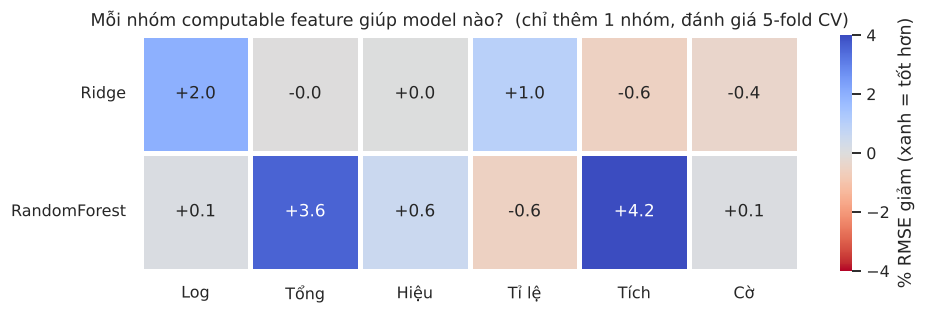

In [13]:
plt.figure(figsize=(9, 3))
sns.heatmap(gain, annot=True, fmt='+.1f', cmap='coolwarm_r', center=0, vmin=-4, vmax=4,
            linewidths=2, linecolor='white', annot_kws={'size': 11},
            cbar_kws={'label': '% RMSE giảm (xanh = tốt hơn)'})
plt.title('Mỗi nhóm computable feature giúp model nào?  (chỉ thêm 1 nhóm, đánh giá 5-fold CV)')
plt.xlabel(''); plt.ylabel('')
plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

**Đây là kết quả quan trọng nhất của notebook.** Cùng một nhóm feature nhưng tác dụng lên hai model lại gần như ngược nhau:

| Nhóm | Ridge (tuyến tính) | RandomForest (cây) | Giải thích |
|---|---|---|---|
| **Log** | **+2.0%** | ≈ 0 | Log là phép **phi tuyến**, Ridge không tự làm được. Với cây, log là hàm đơn điệu: chia theo `LotArea > 10000` hay `log_LotArea > 9.21` đều cho cùng một kết quả, nên cây **không bị ảnh hưởng**. |
| **Tổng** | 0.0 | **+3.6%** | `TotalSF` = tổng 3 cột đã có. Ridge vốn đã cộng các cột với trọng số, nên thêm tổng **không mang thông tin mới**. Cây mỗi lần chỉ xét **một** feature, rất khó tự "cộng" 3 cột, nên đưa sẵn tổng cho nó thì có ích. |
| **Hiệu** | 0.0 | +0.6% | Cùng lý do với tổng: `HouseAge = YrSold − YearBuilt` vẫn là tổ hợp tuyến tính. |
| **Tỉ lệ** | **+1.0%** | −0.6% | Phép chia là phi tuyến nên giúp Ridge. Với cây thì gần như không đổi. |
| **Tích** | −0.6% | **+4.2%** | Đúng như dự đoán ở 2.3: trên thang log, quan hệ nhân đã thành quan hệ cộng nên tích không giúp Ridge. Cây không tự nhân hai feature được nên được lợi nhiều nhất. |
| **Cờ** | −0.4% | ≈ 0 | Thông tin gần như đã có sẵn. Ví dụ, cây chia theo ngưỡng `2ndFlrSF > 0` thì chính là `Has2ndFlr`. |

*(Các thay đổi dưới khoảng 0.5% có thể chỉ là nhiễu.)*

**Bài học:** đúng như Duboue nói, computable feature có giá trị khi nó cung cấp **phép toán mà model không tự làm được**:
- Model **tuyến tính** cần các phép **phi tuyến**: log, chia, (và tích nếu target không được lấy log).
- Model **cây** cần các phép **kết hợp nhiều feature**: tổng, tích.

Vì vậy, chọn computable feature phải dựa vào **model sẽ dùng**, không chỉ dựa vào tương quan với target.

## 4. Phân tích lỗi (error analysis)
Theo vòng lặp feature engineering của Duboue, sau khi train cần xem model **sai ở đâu** để nghĩ ra feature cho vòng tiếp theo. Ba căn bị dự đoán sai nhiều nhất được khoanh tròn đen.

     GrLivArea  OverallQual  YearBuilt SaleCondition Neighborhood  gia_that  gia_du_doan
197       1317            4       1920        Normal       IDOTRR   40000.0      88000.0
134        480            2       1949       Abnorml       IDOTRR   35000.0      58000.0
227        968            4       1927        Normal      OldTown   65000.0     105000.0


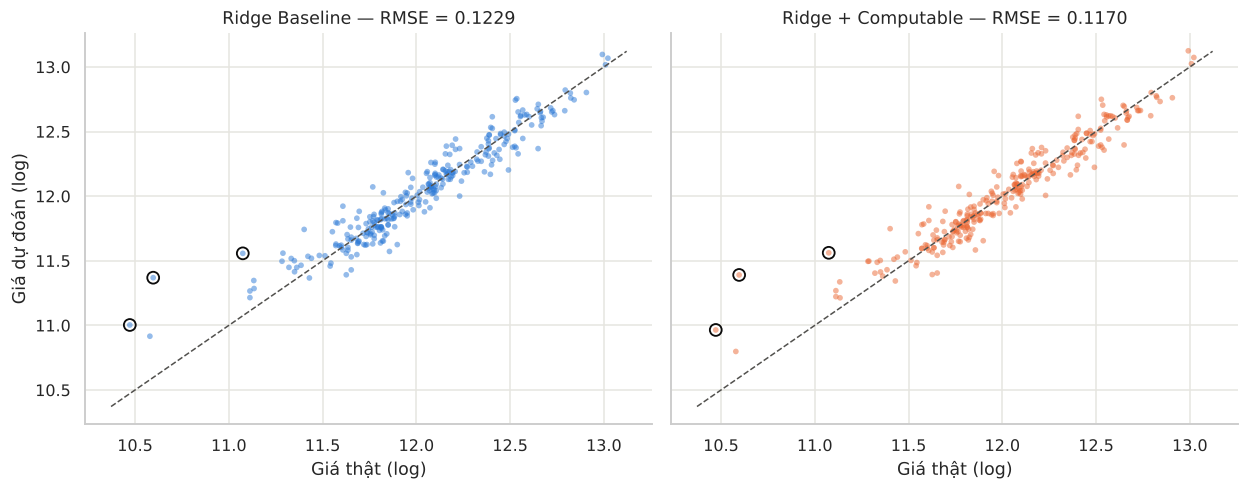

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)
for ax, (name, Xva, color) in zip(axes, [('Baseline', X_val, BLUE), ('+ Computable', Xva_cf, ORANGE)]):
    pred = models[('Ridge', name)].predict(Xva)
    err = np.abs(pred - y_val)
    ax.scatter(y_val, pred, s=14, alpha=0.5, color=color, edgecolor='none')
    worst = err.nlargest(3).index
    ax.scatter(y_val[worst], pred[worst], s=60, facecolor='none', edgecolor='#0b0b0b', lw=1.2)
    lims = [y_val.min() - 0.1, y_val.max() + 0.1]
    ax.plot(lims, lims, color='#52514e', lw=1, ls='--')
    ax.set(title=f'Ridge {name} — RMSE = {rmse(y_val, pred):.4f}', xlabel='Giá thật (log)',
           ylabel='Giá dự đoán (log)' if name == 'Baseline' else '')
plt.tight_layout(); plt.show()

pred_cf = models[('Ridge', '+ Computable')].predict(Xva_cf)
worst = pd.Series(np.abs(pred_cf - y_val)).nlargest(3).index
print(X_val.loc[worst, ['GrLivArea', 'OverallQual', 'YearBuilt', 'SaleCondition', 'Neighborhood']]
      .assign(gia_that=np.exp(y_val[worst]).round(-3), gia_du_doan=np.exp(pred_cf[worst]).round(-3)))

**Nhận xét:**
- Sau khi thêm feature, các điểm sát đường chéo hơn một chút, nhưng **ba căn sai nhiều nhất vẫn là ba căn đó** ở cả hai phiên bản.
- Cả ba đều là **nhà rẻ, cũ (xây 1920–1949), chất lượng thấp, ở khu IDOTRR/OldTown**. Giá thật từ 35k đến 65k nhưng model đoán từ 58k đến 105k, tức là **đánh giá quá cao những căn rất rẻ**.
- Các computable feature hiện tại (diện tích, tuổi, …) chưa giải thích được nhóm này. Gợi ý cho vòng tiếp theo:
  - feature tương tác giữa **khu phố và tình trạng nhà** (ví dụ `OverallCond` × khu phố cũ);
  - **giá trung vị theo khu phố** (target encoding). Feature này dùng thống kê của target nên **bắt buộc chỉ được tính trên train** (hoặc tính out-of-fold), nếu không sẽ bị leakage.

## 5. Tổng kết

1. **Computable feature là một kỹ thuật bên trong feature engineering**, thuộc nhóm *mở rộng feature*: tạo feature mới từ feature cũ bằng log, tổng, hiệu, tỉ lệ, tích và cờ.
2. Thêm 23 computable feature giúp **cả Ridge và RandomForest đều giảm RMSE** (Ridge 0.1229 xuống 0.1170 trên val; RandomForest 0.1406 xuống 0.1337 trên CV).
3. **Một feature tốt hay không còn tùy vào model**:
   - tổng và hiệu **vô ích với Ridge** (vì Ridge đã tự cộng được) nhưng **có ích với cây**;
   - log **vô ích với cây** (vì log là hàm đơn điệu) nhưng **có ích với Ridge**.
4. **Tương quan cao chưa chắc giúp model**: `Qual_x_TotalSF` có tương quan cao nhất (0.88) nhưng nhóm tích lại không giúp được Ridge.
5. Computable feature **trùng thông tin** với feature gốc, nên bước tiếp theo tự nhiên là **feature selection** (chương 4).
6. Các feature tính **theo từng dòng** thì an toàn với leakage. Feature dùng **thống kê của target** thì chỉ được tính trên train.